## Problema - Organización y búsqueda de productos en una tienda

**Instrucción:** completa esta plantilla con tu diseño y desarrollo. Evita incluir soluciones generadas automáticamente.



In [ ]:
# @title Ingrese datos
nombre_estudiante = "felipe gomez parra" # @param {"type":"string"}
carnet = 1000115115 # @param {"type":"integer"}


## 1) Descripción del problema **[1 pts]**

Una empresa de transporte urbano necesita un sistema que represente las conexiones entre las estaciones de su red. Para ello, se utilizará un grafo no dirigido, almacenado mediante una lista de adyacencia.
El sistema permitirá consultar las conexiones directas de cada estación, realizar recorridos utilizando los algoritmos BFS (búsqueda en anchura) y DFS (búsqueda en profundidad), encontrar una ruta con la menor cantidad de conexiones entre dos estaciones y agregar nuevas estaciones.
El objetivo es facilitar el análisis de la red de transporte, conocer cómo están conectadas las estaciones y encontrar rutas eficientes. Además, el programa debe validar las estaciones ingresadas y evitar conexiones duplicadas.

 Requerimientos Funcionales (RF)

RF01. El sistema debe representar la red de transporte o conexiones mediante una estructura de datos basada en listas de adyacencia, permitiendo procesar  las estaciones y mostrar de manera detallada las conexiones directas relacionadas a cada una de ellas para la consulta del usuario.

RF02. Recorrido por amplitud (BFS). El sistema debe implementar y ejecutar el algoritmo de Búsqueda en Anchura (Breadth-First Search) a partir de una estación de origen seleccionada, calculando y mostrando secuencialmente el orden exacto de visita junto con el nivel o distancia correspondiente a cada estación alcanzada.

RF03. Recorrido por profundidad (DFS). El sistema debe implementar y ejecutar el algoritmo de Búsqueda en Profundidad (Depth-First Search) iniciando de una estación inicial designada, explorando las ramas de la red y mostrando de forma clara el orden progresivo en el que se visitan las estaciones.

RF04. Búsqueda de ruta óptima. El sistema debe permitir al usuario seleccionar una estación de partida y una de destino para calcular y desplegar la ruta con el menor número de conexiones o saltos intermedios, usando por eso el algoritmo de búsqueda por amplitud.

RF05. Dinamismo y ampliación de la red. El sistema debe proveer una funcionalidad interactiva para incorporar nuevas estaciones a la red existente, enlazándolas con los nodos correspondientes y actualizando de forma inmediata y automática la estructura global del sistema.


Requerimientos No Funcionales RNF

RNF01. Organización de la información.

RNF02. Integridad de las conexiones.

RNF03. Eficiencia de los algoritmos.

RNF04. Facilidad de uso.

RNF05. Mantenibilidad y claridad del código.

## 3) Historias de usuario **[2 pts]**
HU01. Consultar las conexiones

Historia: Como usuario, quiero consultar las estaciones y sus conexiones directas para conocer la estructura de la red de transporte.

Criterios de aceptación:

1. El sistema muestra todas las estaciones registradas.
2. Cada estación aparece junto con sus estaciones vecinas.
3. No se muestran conexiones duplicadas.

HU02. Recorrer la red

Historia: Como usuario, quiero ejecutar BFS y DFS desde una estación seleccionada para conocer el orden en que se recorren las estaciones.

Criterios de aceptación:

1. El sistema solicita una estación inicial válida.
2. El sistema muestra el orden de visita de BFS y DFS.
3. Si la estación no existe, muestra un mensaje de error.

HU03. Encontrar la ruta más corta

Historia: Como usuario, quiero encontrar una ruta entre dos estaciones que requiera la menor cantidad de conexiones para llegar a mi destino de manera eficiente.

Criterios de aceptación:
1. El sistema solicita una estación de origen y otra de destino.
2. El sistema muestra una ruta con el menor número de conexiones y su cantidad.
3. Si no existe una ruta, informa al usuario.

## 4) Diagramas de flujo **[5 pts]**

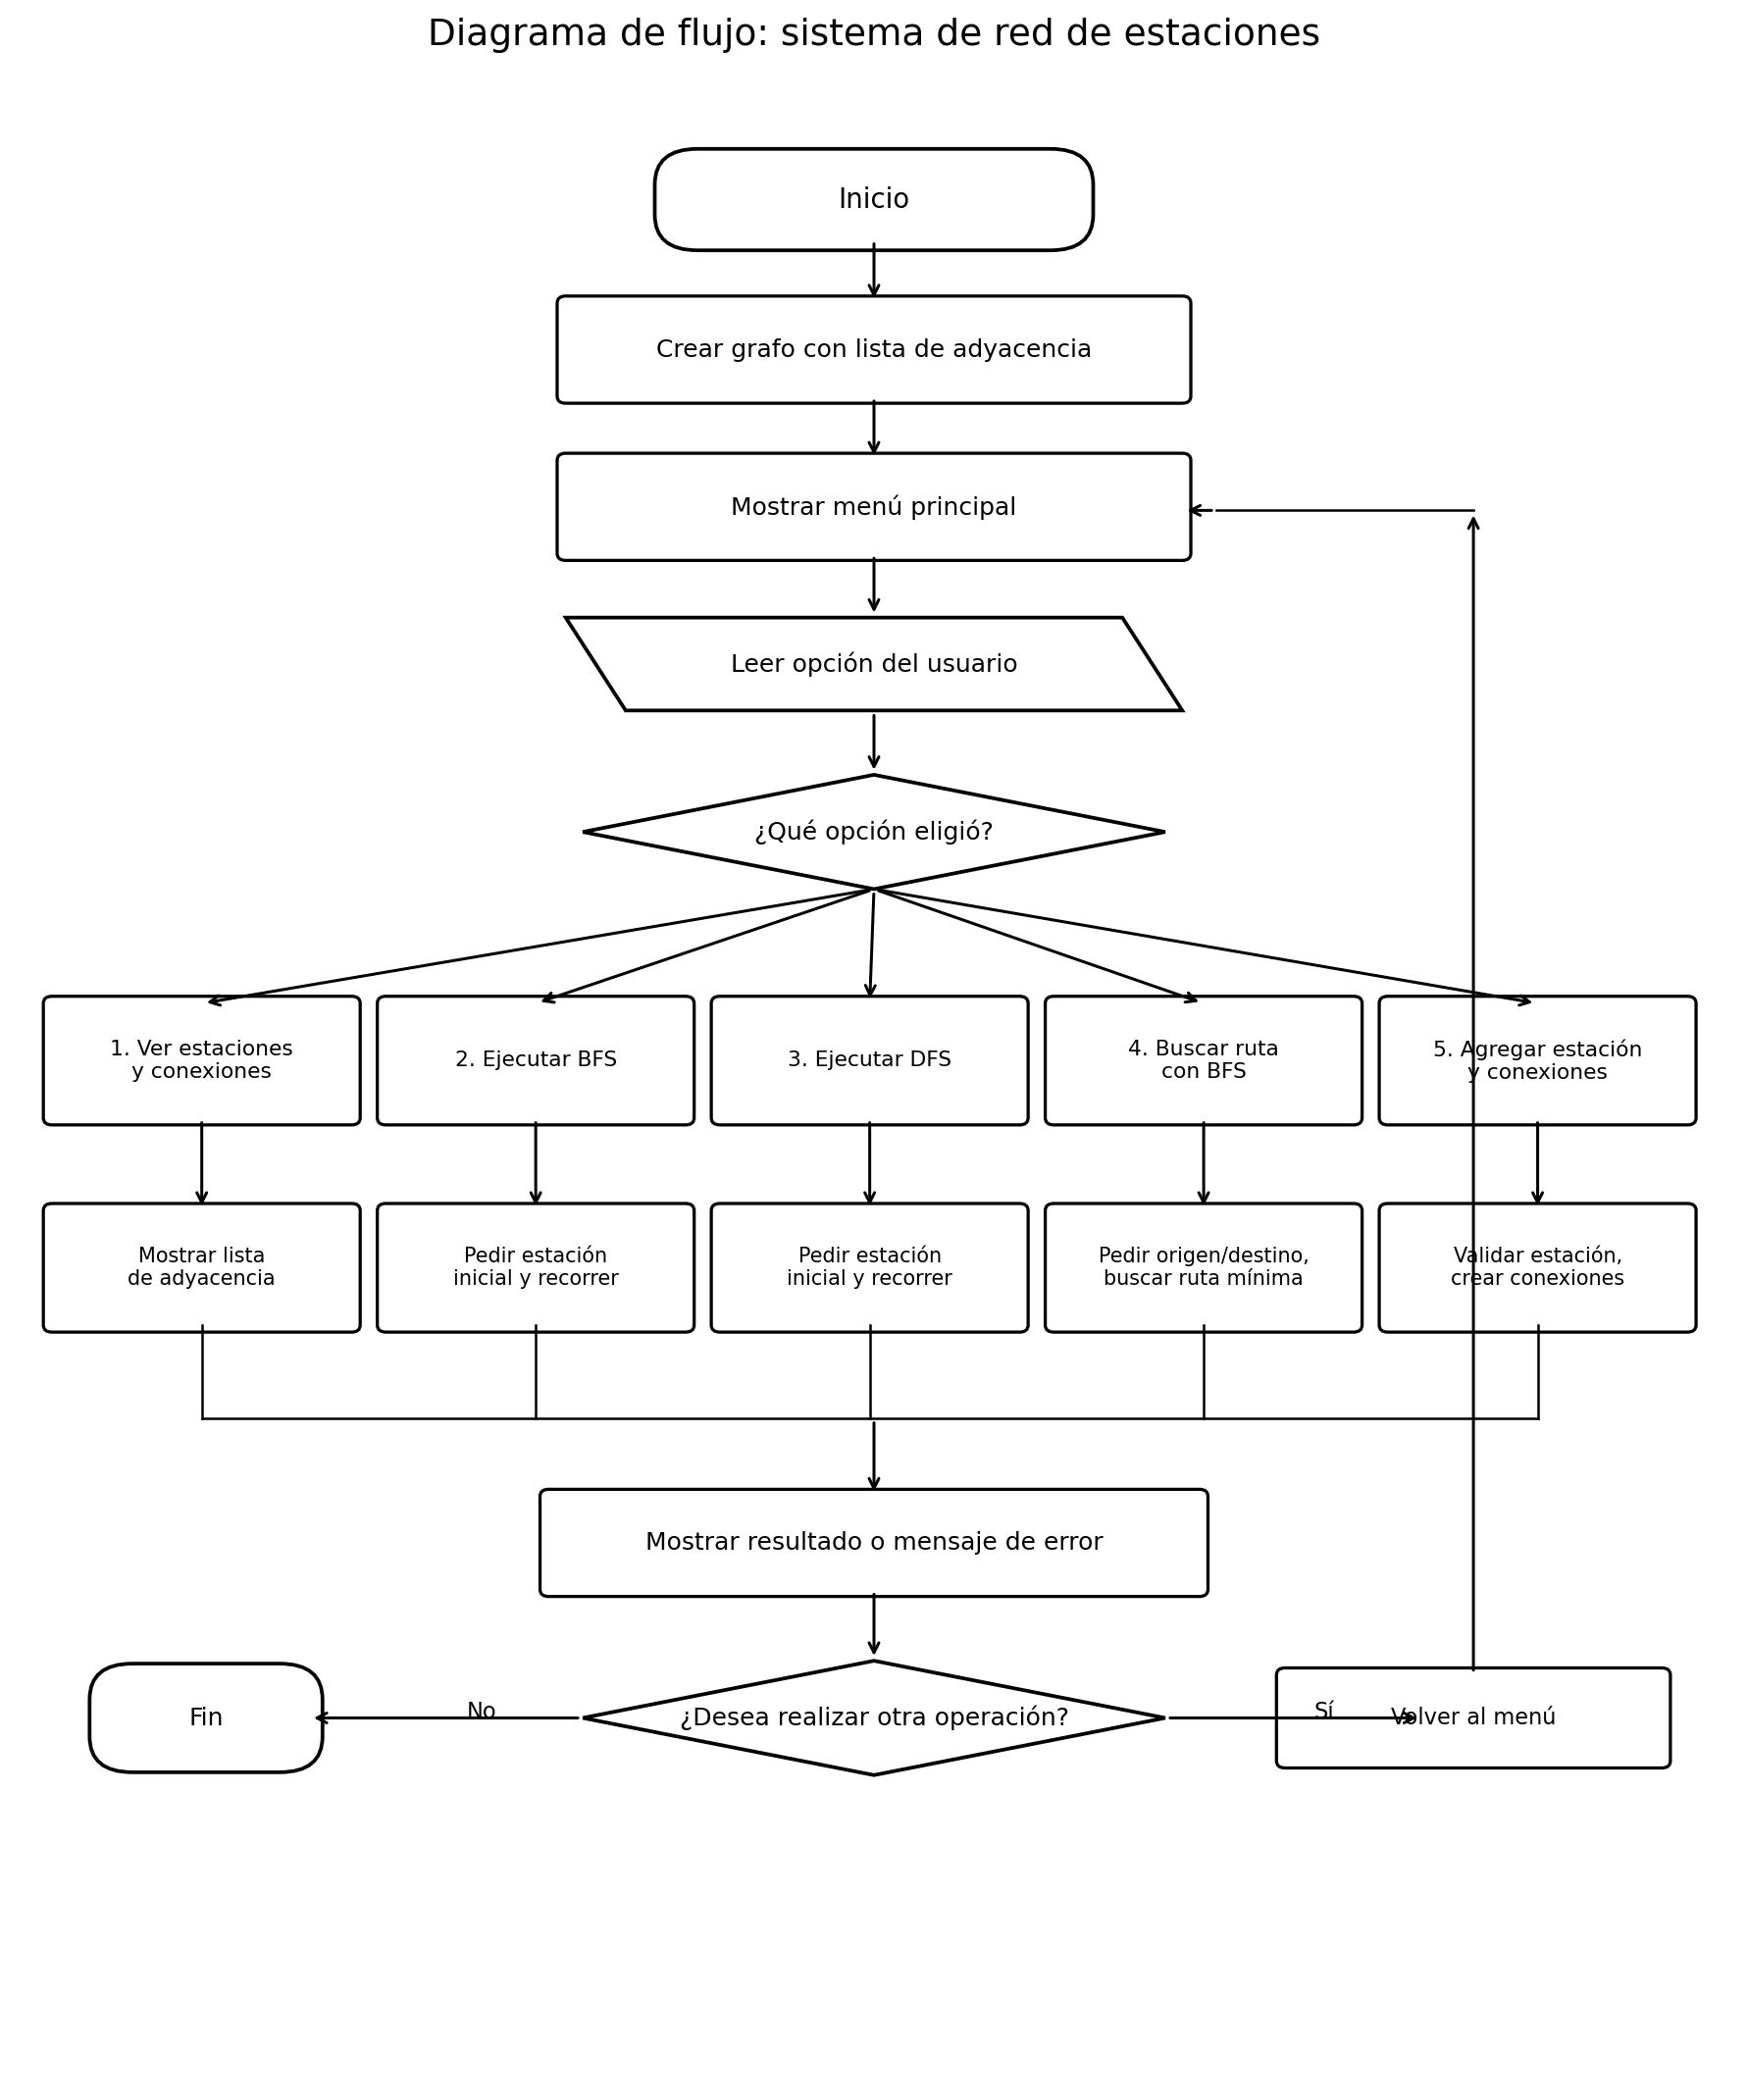

El diagrama de flujo describe el funcionamiento integral de un sistema de red de estaciones que, tras inicializar un grafo mediante una lista de adyacencia, despliega un menú interactivo donde el usuario puede elegir entre consultar las conexiones, ejecutar recorridos BFS o DFS, buscar rutas mínimas o agregar nuevas estaciones, procesando cada selección para mostrar el resultado correspondiente y ofreciendo la alternativa de repetir el ciclo o finalizar la ejecución.

Para evaluar la eficiencia del sistema, se definen las variables V para representar la cantidad de estaciones o vértices y E para la cantidad de conexiones o aristas. Dado que en los algoritmos de recorrido cada estación se procesa como máximo una vez junto con sus conexiones, la función de tiempo general se modela mediante la ecuación lineal T(V,E) = c0 + c1V + c2E, cuya complejidad asintótica se simplifica a O(V + E), indicando que el costo temporal crece de manera proporcional al tamaño total de la red.

Las diferentes operaciones del programa presentan complejidades adaptadas a su propósito estructural. Tanto la visualización de la lista de adyacencia como la ejecución completa de los recorridos BFS y DFS, al igual que la búsqueda de rutas mínimas en el peor escenario, operan en O(V + E). Por el contrario, la inserción de una nueva estación conectada a k nodos vecinos se realiza de forma directa y eficiente con un costo de O(k) en promedio.

El comportamiento del algoritmo también varía de forma significativa entre escenarios ideales y desfavorables. En el mejor caso, la búsqueda de una ruta mediante BFS alcanza un tiempo de O(1) cuando la estación de origen y la de destino son idénticas, permitiendo que el sistema retorne la respuesta de inmediato sin realizar exploraciones. No obstante, en el peor caso, la búsqueda o el recorrido completo exige explorar toda la red, situándose en O(V + E). En redes densas, donde el número de conexiones se aproxima al máximo posible según la fórmula E = V(V - 1) / 2, al considerar V = n, la complejidad del peor caso se eleva de manera cuadrática a O(n al cuadrado), mientras que en redes dispersas donde E es del orden de V, el costo se mantiene lineal en O(V).

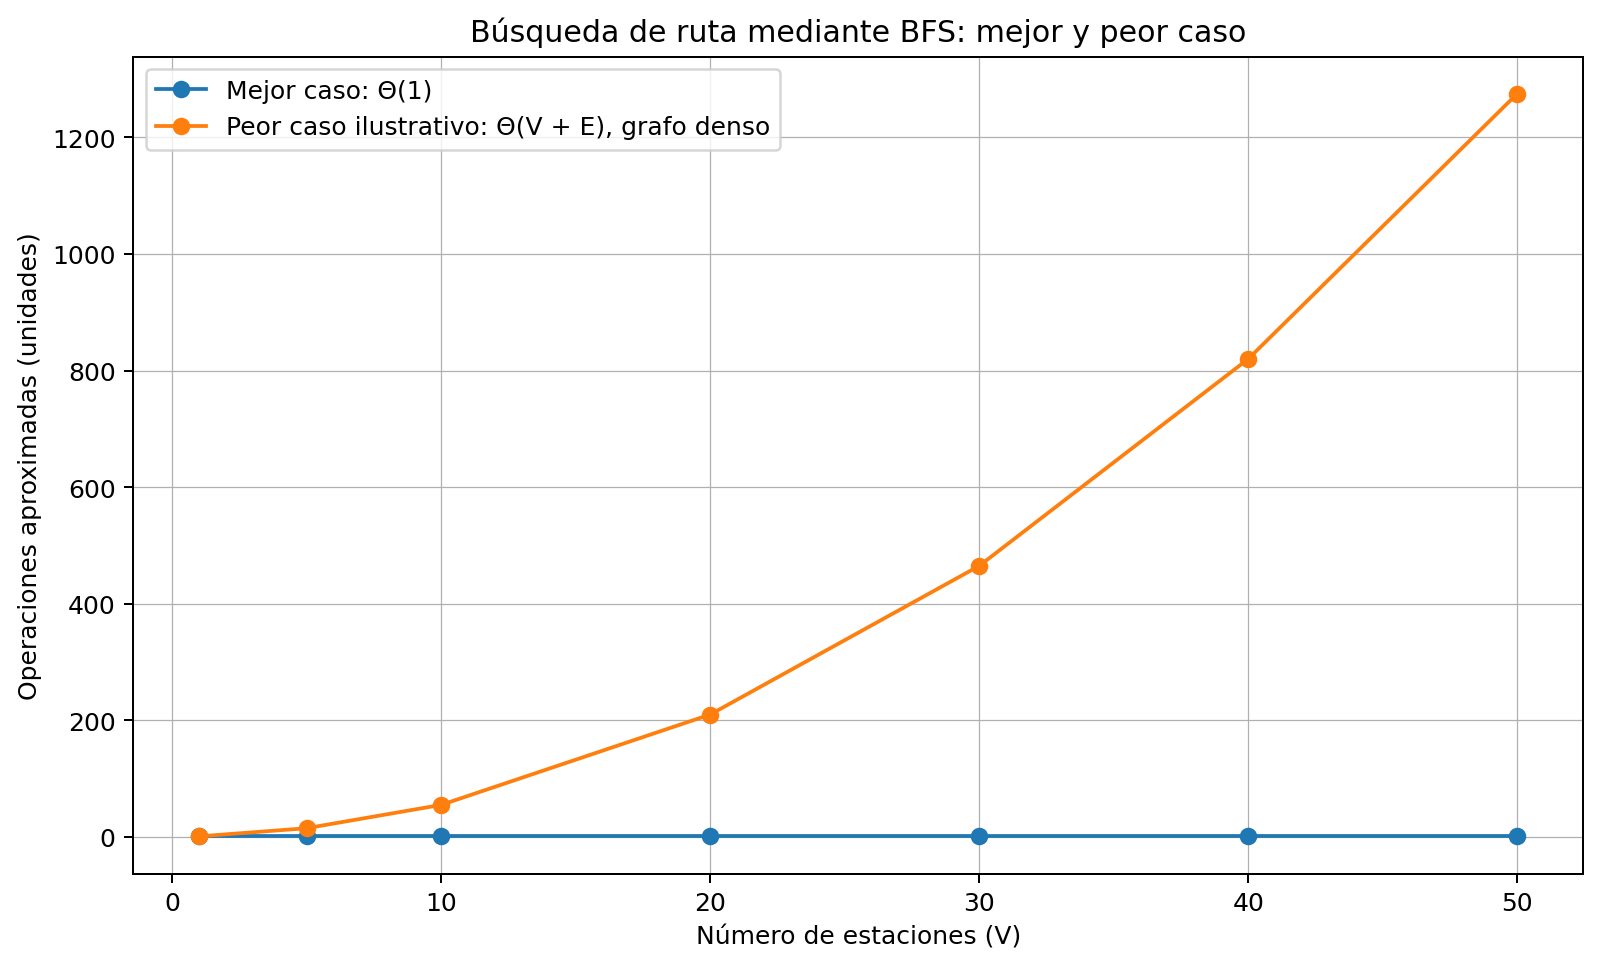

## 6) Código funcional **[15 pts]**
Incluye tu implementación completa.

No pegues código incompleto; debe ser ejecutable.


In [24]:
from collections import deque

# Red inicial de estaciones (grafo no dirigido)
grafo = {
    "Central": ["Norte", "Museo"],
    "Norte": ["Central", "Parque", "Universidad"],
    "Museo": ["Central", "Hospital"],
    "Parque": ["Norte"],
    "Universidad": ["Norte", "Terminal"],
    "Hospital": ["Museo", "Terminal"],
    "Terminal": ["Universidad", "Hospital"],
}


def saludar_y_continuar():
  """Saluda al usuario y pregunta si desea continuar o cerrar el programa."""
  print("\n¡Hola! Bienvenido al Sistema de Red de Transporte Urbano.")
  while True:
    respuesta = (
        input("¿Desea continuar utilizando el programa? (si/no): ")
        .strip()
        .lower()
    )
    if respuesta in ["si", "sí", "s"]:
      return True
    elif respuesta in ["no", "n"]:
      print("\nCerrando el programa. ¡Hasta luego!")
      return False
    else:
      print("Respuesta no válida. Por favor, escriba 'si' o 'no'.")


def mostrar_red():
  """Muestra cada estación junto con sus conexiones directas."""
  print("\n--- RED DE ESTACIONES Y CONEXIONES ---")
  for estacion, vecinos in grafo.items():
    print(f"{estacion}: {', '.join(vecinos)}")


def bfs(inicio):
  """Recorrido BFS usando una cola."""
  if inicio not in grafo:
    raise ValueError(f"La estación '{inicio}' no existe en la red.")

  visitados = {inicio}
  cola = deque([(inicio, 0)])
  orden = []
  niveles = {}

  while cola:
    actual, nivel = cola.popleft()
    orden.append(actual)
    niveles[actual] = nivel

    for vecino in grafo[actual]:
      if vecino not in visitados:
        visitados.add(vecino)
        cola.append((vecino, nivel + 1))

  return orden, niveles


def dfs(inicio):
  """Recorrido DFS mediante recursividad."""
  if inicio not in grafo:
    raise ValueError(f"La estación '{inicio}' no existe en la red.")

  visitados = set()
  orden = []

  def explorar(nodo):
    visitados.add(nodo)
    orden.append(nodo)
    for vecino in grafo[nodo]:
      if vecino not in visitados:
        explorar(vecino)

  explorar(inicio)
  return orden


def ruta_mas_corta(origen, destino):
  """Buscar la ruta más corta con BFS."""
  if origen not in grafo:
    raise ValueError(f"La estación de origen '{origen}' no existe.")
  if destino not in grafo:
    raise ValueError(f"La estación de destino '{destino}' no existe.")

  if origen == destino:
    return [origen], 0

  visitados = {origen}
  cola = deque([origen])
  padre = {origen: None}

  while cola:
    actual = cola.popleft()
    if actual == destino:
      break

    for vecino in grafo[actual]:
      if vecino not in visitados:
        visitados.add(vecino)
        padre[vecino] = actual
        cola.append(vecino)

  if destino not in padre:
    return None, 0

  ruta = []
  actual = destino
  while actual is not None:
    ruta.append(actual)
    actual = padre[actual]
  ruta.reverse()

  conexiones = len(ruta) - 1
  return ruta, conexiones


def agregar_estacion():
  """Agregar una nueva estación y conectarla."""
  print("\n--- AGREGAR NUEVA ESTACIÓN ---")
  nueva = input("Ingrese el nombre de la nueva estación: ").strip()

  if nueva in grafo:
    print(f"Error: La estación '{nueva}' ya existe.")
    return

  print(
      "Estaciones disponibles para conectar:"
      f" {', '.join(list(grafo.keys()))}"
  )
  c1 = input("Ingrese la primera estación existente a conectar: ").strip()
  c2 = input("Ingrese la segunda estación existente a conectar: ").strip()

  conexiones = [c1, c2]
  for vec in conexiones:
    if vec not in grafo:
      print(f"Error: La estación '{vec}' no existe en la red.")
      return

  grafo[nueva] = []
  for vec in conexiones:
    if vec not in grafo[nueva]:
      grafo[nueva].append(vec)
    if nueva not in grafo[vec]:
      grafo[vec].append(nueva)

  print(f"¡Estación '{nueva}' agregada y conectada exitosamente!")


# --- MENÚ INTERACTIVO PRINCIPAL ---
def menu():
  while True:
    # Llamamos a la función de saludo y validación para iniciar o reiniciar
    if not saludar_y_continuar():
      break

    while True:
      print("\n===============================")
      print("   SISTEMA DE RED DE TRANSPORTE")
      print("===============================")
      print("1. Mostrar red de estaciones")
      print("2. Ejecutar BFS y DFS desde estación inicial")
      print("3. Buscar ruta más corta entre dos estaciones")
      print("4. Agregar una nueva estación y conexiones")
      print("5. Reiniciar o salir del sistema")

      opcion = input("Seleccione una opción (1-5): ").strip()

      if opcion == "1":
        mostrar_red()

      elif opcion == "2":
        inicio = input("\nIngrese la estación inicial: ").strip()
        try:
          orden_b, niveles_b = bfs(inicio)
          print(f"\nRecorrido BFS desde {inicio}:", " -> ".join(orden_b))
          print("Niveles:", niveles_b)

          orden_d = dfs(inicio)
          print(f"Recorrido DFS desde {inicio}:", " -> ".join(orden_d))
        except ValueError as e:
          print(f"Error: {e}")

      elif opcion == "3":
        origen = input("\nEstación de origen: ").strip()
        destino = input("Estación de destino: ").strip()
        try:
          ruta, cant = ruta_mas_corta(origen, destino)
          if ruta:
            print("\nRuta encontrada:", " -> ".join(ruta))
            print(f"Cantidad de conexiones: {cant}")
          else:
            print(f"\nNo existe una ruta entre {origen} y {destino}.")
        except ValueError as e:
          print(f"Error: {e}")

      elif opcion == "4":
        agregar_estacion()

      elif opcion == "5":
        # Al elegir salir del submenú, rompemos para volver a preguntar con la función de saludo
        break
      else:
        print("\nOpción inválida. Por favor, elija un número entre 1 y 5.")


if __name__ == "__main__":
  menu()


¡Hola! Bienvenido al Sistema de Red de Transporte Urbano.

   SISTEMA DE RED DE TRANSPORTE
1. Mostrar red de estaciones
2. Ejecutar BFS y DFS desde estación inicial
3. Buscar ruta más corta entre dos estaciones
4. Agregar una nueva estación y conexiones
5. Reiniciar o salir del sistema

--- RED DE ESTACIONES Y CONEXIONES ---
Central: Norte, Museo
Norte: Central, Parque, Universidad
Museo: Central, Hospital
Parque: Norte
Universidad: Norte, Terminal
Hospital: Museo, Terminal
Terminal: Universidad, Hospital

   SISTEMA DE RED DE TRANSPORTE
1. Mostrar red de estaciones
2. Ejecutar BFS y DFS desde estación inicial
3. Buscar ruta más corta entre dos estaciones
4. Agregar una nueva estación y conexiones
5. Reiniciar o salir del sistema
Error: La estación de origen 'universidad' no existe.

   SISTEMA DE RED DE TRANSPORTE
1. Mostrar red de estaciones
2. Ejecutar BFS y DFS desde estación inicial
3. Buscar ruta más corta entre dos estaciones
4. Agregar una nueva estación y conexiones
5. Reinic

KeyboardInterrupt: Interrupted by user

## 7) Tests aplicados **[15 pts]**

In [26]:
# --- PRUEBAS AUTOMATIZADAS CON ASSERT ---

# 1. Probar la visualización o existencia inicial del grafo
assert "Central" in grafo
assert "Norte" in grafo["Central"]
assert "Museo" in grafo["Central"]

# 2. Probar recorrido BFS desde Central
orden_bfs, niveles_bfs = bfs("Central")
assert orden_bfs[0] == "Central"
assert niveles_bfs["Central"] == 0
assert "Norte" in niveles_bfs and niveles_bfs["Norte"] == 1
assert "Terminal" in niveles_bfs and niveles_bfs["Terminal"] == 3

# 3. Probar recorrido DFS desde Central
orden_dfs = dfs("Central")
assert orden_dfs[0] == "Central"
assert len(orden_dfs) == len(grafo)  # Debe visitar todas las estaciones

# 4. Probar búsqueda de ruta más corta (Central a Terminal)
ruta, conexiones = ruta_mas_corta("Central", "Terminal")
assert ruta[0] == "Central"
assert ruta[-1] == "Terminal"
assert conexiones == 3

# 5. Probar manejo de errores con estaciones inexistentes
try:
  bfs("EstacionInventada")
  assert False, "Debería haber lanzado un ValueError"
except ValueError:
  pass  # La prueba pasa si captura el error correctamente

print("¡Todas las pruebas con assert pasaron exitosamente!")

¡Todas las pruebas con assert pasaron exitosamente!
